<a href="https://colab.research.google.com/github/mmarzafaridob24ti-sys/Project_ProbStat/blob/main/Projek_Probstat_Kode.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

# Upload file Excel
uploaded = files.upload()

# Membaca dataset
file_name = list(uploaded.keys())[0]
df = pd.read_excel(file_name)

# Melihat 5 data pertama
df.head()

Saving 3TIC_10_HargaTBSPenetapan_TimProvinsi.xlsx to 3TIC_10_HargaTBSPenetapan_TimProvinsi.xlsx


,Periode,USD/IDR,Kelapa Sawit Umur,Indeks K (%),Rendemen CPO (%),Harga CPO (Rp/Kg),Rendemen Kernel (%),Harga Kernel (Rp/Kg),Harga TBS (Rp/Kg)
0,Minggu 1,"16.203,20",3,89.88,17.07,14738.3,3.99,10788.61,2651.06
1,Minggu 1,"16.203,20",4,89.88,18.34,14738.3,4.42,10788.61,2863.56
2,Minggu 1,"16.203,20",5,89.88,19.17,14738.3,4.61,10788.61,2991.43
3,Minggu 1,"16.203,20",6,89.88,19.79,14738.3,4.74,10788.61,3085.79
4,Minggu 1,"16.203,20",7,89.88,20.22,14738.3,4.84,10788.61,3152.46


In [ ]:
# Informasi dataset
df.info()

# Ukuran data
print("Jumlah baris:", df.shape[0])
print("Jumlah kolom:", df.shape[1])

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 870 entries, 0 to 869
Data columns (total 9 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Periode               870 non-null    object 
 1   USD/IDR               870 non-null    object 
 2   Kelapa Sawit Umur     870 non-null    object 
 3   Indeks K (%)          870 non-null    float64
 4   Rendemen CPO (%)      870 non-null    float64
 5   Harga CPO (Rp/Kg)     870 non-null    float64
 6   Rendemen Kernel (%)   870 non-null    float64
 7   Harga Kernel (Rp/Kg)  870 non-null    float64
 8   Harga TBS (Rp/Kg)     870 non-null    float64
dtypes: float64(6), object(3)
memory usage: 61.3+ KB
Jumlah baris: 870
Jumlah kolom: 9


In [ ]:
# Membersihkan USD/IDR agar menjadi numerik

df['USD/IDR'] = (
    df['USD/IDR']
    .astype(str)
    .str.replace('.', '', regex=False)
    .str.replace(',', '.', regex=False)
)

df['USD/IDR'] = pd.to_numeric(df['USD/IDR'], errors='coerce')


# Cek data kosong
df.isnull().sum()

,0
Periode,0
USD/IDR,0
Kelapa Sawit Umur,0
Indeks K (%),0
Rendemen CPO (%),0
Harga CPO (Rp/Kg),0
Rendemen Kernel (%),0
Harga Kernel (Rp/Kg),0
Harga TBS (Rp/Kg),0


In [ ]:
# Variabel numerik yang dianalisis

variabel = [
    'USD/IDR',
    'Harga CPO (Rp/Kg)',
    'Harga Kernel (Rp/Kg)',
    'Harga TBS (Rp/Kg)'
]


# Statistik deskriptif

statistik = df[variabel].describe().T


# Tambahan median, varians

statistik['median'] = df[variabel].median()
statistik['variance'] = df[variabel].var()


# Susun urutan kolom

statistik = statistik[
    [
        'count',
        'mean',
        'median',
        'std',
        'variance',
        'min',
        'max'
    ]
]


statistik

,count,mean,median,std,variance,min,max
USD/IDR,870.0,16465.468586,16405.80,190.785280,3.639902e+04,16203.20,16849.00
Harga CPO (Rp/Kg),870.0,14053.208747,14126.10,525.031792,2.756584e+05,12766.61,15032.76
Harga Kernel (Rp/Kg),870.0,11878.977839,11649.63,1128.590453,1.273716e+06,9572.06,13770.81
Harga TBS (Rp/Kg),870.0,2978.599563,2993.93,304.077671,9.246323e+04,1576.36,3719.42


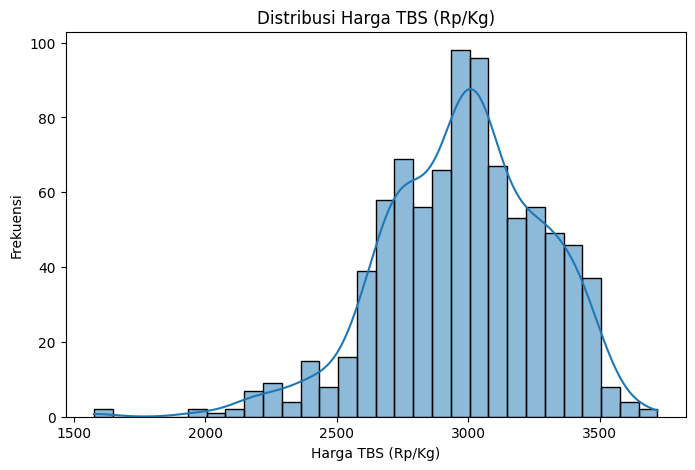

In [ ]:
plt.figure(figsize=(8,5))

sns.histplot(
    df['Harga TBS (Rp/Kg)'],
    bins=30,
    kde=True
)

plt.title('Distribusi Harga TBS (Rp/Kg)')
plt.xlabel('Harga TBS (Rp/Kg)')
plt.ylabel('Frekuensi')

plt.show()

In [ ]:
# Menghitung rata-rata harga TBS tiap minggu

harga_mingguan = (
    df.groupby('Periode')['Harga TBS (Rp/Kg)']
    .mean()
)


harga_mingguan

,Harga TBS (Rp/Kg)
Periode,
Minggu 1,2992.145789
Minggu 10,2983.841429
Minggu 11,3205.580526
Minggu 12,3220.299474
Minggu 13,3002.973684
Minggu 14,3037.201053
Minggu 15,3109.419474
Minggu 16,3134.991053
Minggu 17,2828.583158


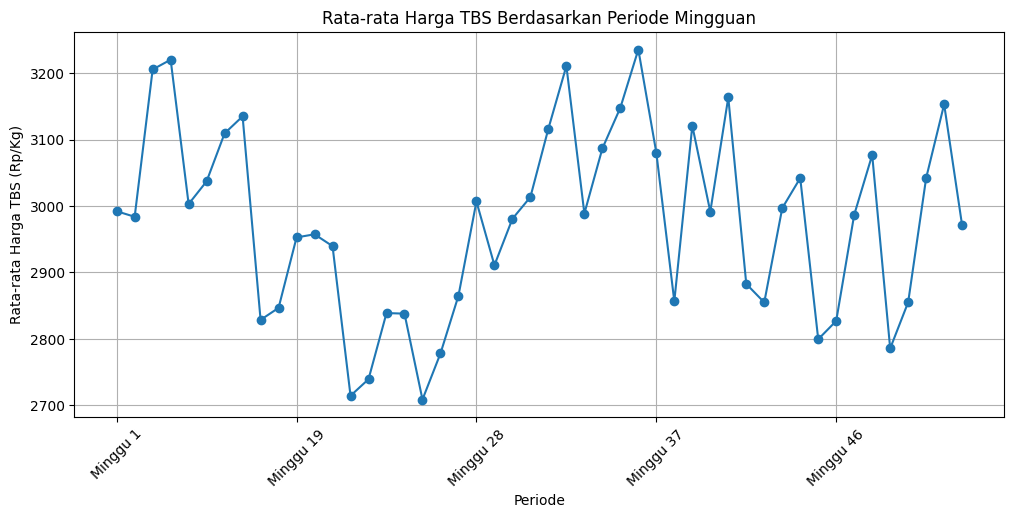

In [ ]:
plt.figure(figsize=(12,5))

harga_mingguan.plot(
    marker='o'
)

plt.title(
    'Rata-rata Harga TBS Berdasarkan Periode Mingguan'
)

plt.xlabel('Periode')
plt.ylabel('Rata-rata Harga TBS (Rp/Kg)')

plt.xticks(rotation=45)

plt.grid(True)

plt.show()

In [ ]:
# Menghitung mean dan standar deviasi

variasi = pd.DataFrame({
    'mean': df[variabel].mean(),
    'std': df[variabel].std()
})


# Menghitung coefficient of variation

variasi['CV (%)'] = (
    variasi['std'] / variasi['mean']
) * 100


variasi

,mean,std,CV (%)
USD/IDR,16465.468586,190.785280,1.158699
Harga CPO (Rp/Kg),14053.208747,525.031792,3.736028
Harga Kernel (Rp/Kg),11878.977839,1128.590453,9.500737
Harga TBS (Rp/Kg),2978.599563,304.077671,10.208746


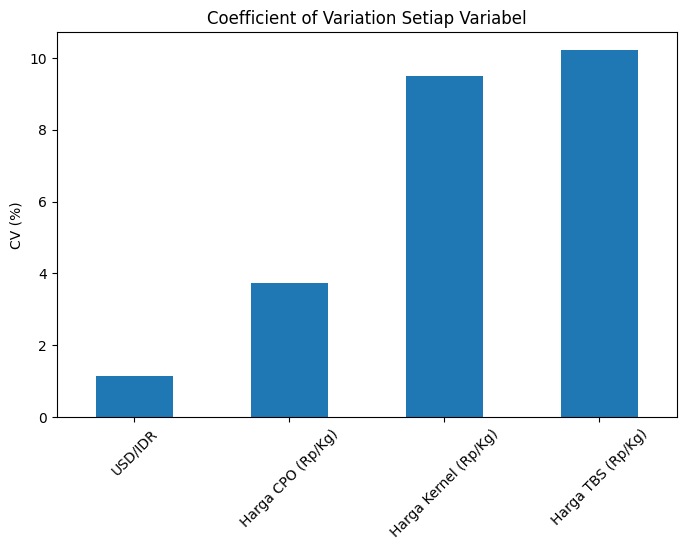

In [ ]:
plt.figure(figsize=(8,5))

variasi['CV (%)'].plot(
    kind='bar'
)

plt.title(
    'Coefficient of Variation Setiap Variabel'
)

plt.ylabel('CV (%)')

plt.xticks(rotation=45)

plt.show()

In [ ]:
df['Kelapa Sawit Umur'].unique()

array([3, 4, 5, 6, 7, 8, 9, datetime.datetime(2026, 10, 20, 0, 0), 21, 22,
       23, 24, 25, 26, 27, 28, 29, 30, '21-24'], dtype=object)

In [ ]:
# Mengubah kolom umur menjadi string

df['Kelapa Sawit Umur'] = df['Kelapa Sawit Umur'].astype(str)


# Perbaiki format tanggal yang salah terbaca
df['Kelapa Sawit Umur'] = df['Kelapa Sawit Umur'].replace(
    {
        '2026-10-20 00:00:00':'10-20'
    }
)


# Cek hasil
df['Kelapa Sawit Umur'].unique()

array(['3', '4', '5', '6', '7', '8', '9', '10-20', '21', '22', '23', '24',
       '25', '26', '27', '28', '29', '30', '21-24'], dtype=object)

In [ ]:
umur_tbs = (
    df.groupby('Kelapa Sawit Umur')
    ['Harga TBS (Rp/Kg)']
    .agg(
        mean='mean',
        min='min',
        max='max',
        std='std'
    )
)


umur_tbs

,mean,min,max,std
Kelapa Sawit Umur,,,,
10-20,3323.252841,2978.43,3719.42,164.551585
21,3103.675625,2679.23,3539.85,271.133117
21-24,2912.623333,2874.66,2980.47,58.895664
22,3063.189375,2639.47,3504.87,275.862885
23,3029.627292,2599.78,3469.09,277.976257
24,2958.273750,2540.53,3371.03,264.711472
25,2328.076471,1576.36,2845.00,248.131712
26,2954.505000,2679.42,3122.20,139.155493
27,2924.405750,2651.62,3090.99,137.885098


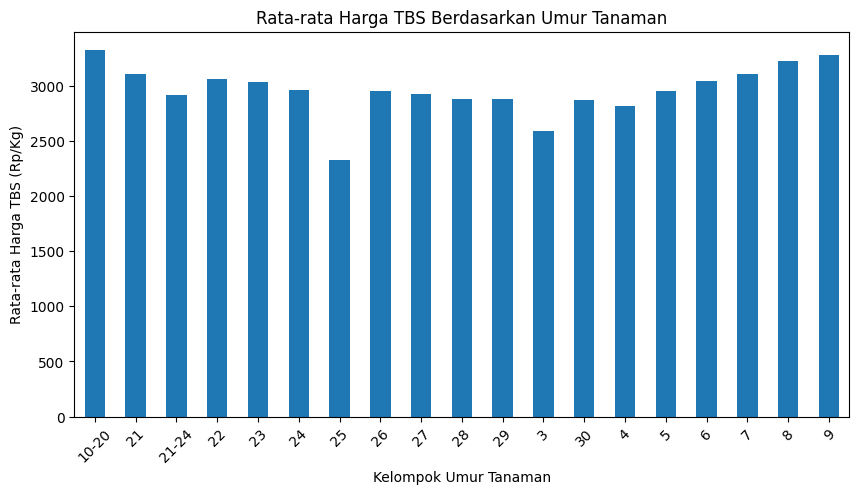

In [ ]:
plt.figure(figsize=(10,5))

umur_tbs['mean'].plot(
    kind='bar'
)

plt.title(
    'Rata-rata Harga TBS Berdasarkan Umur Tanaman'
)

plt.xlabel(
    'Kelompok Umur Tanaman'
)

plt.ylabel(
    'Rata-rata Harga TBS (Rp/Kg)'
)

plt.xticks(rotation=45)

plt.show()